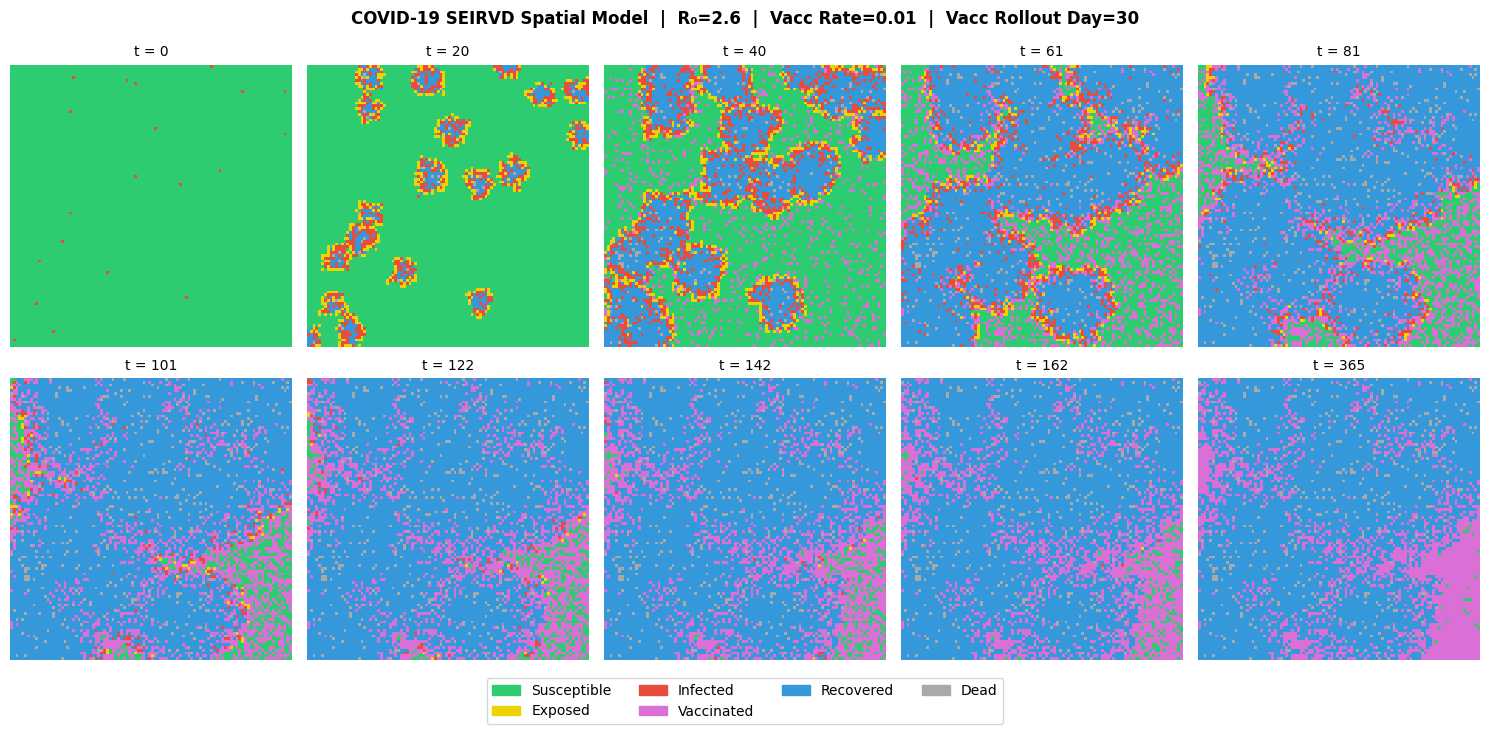

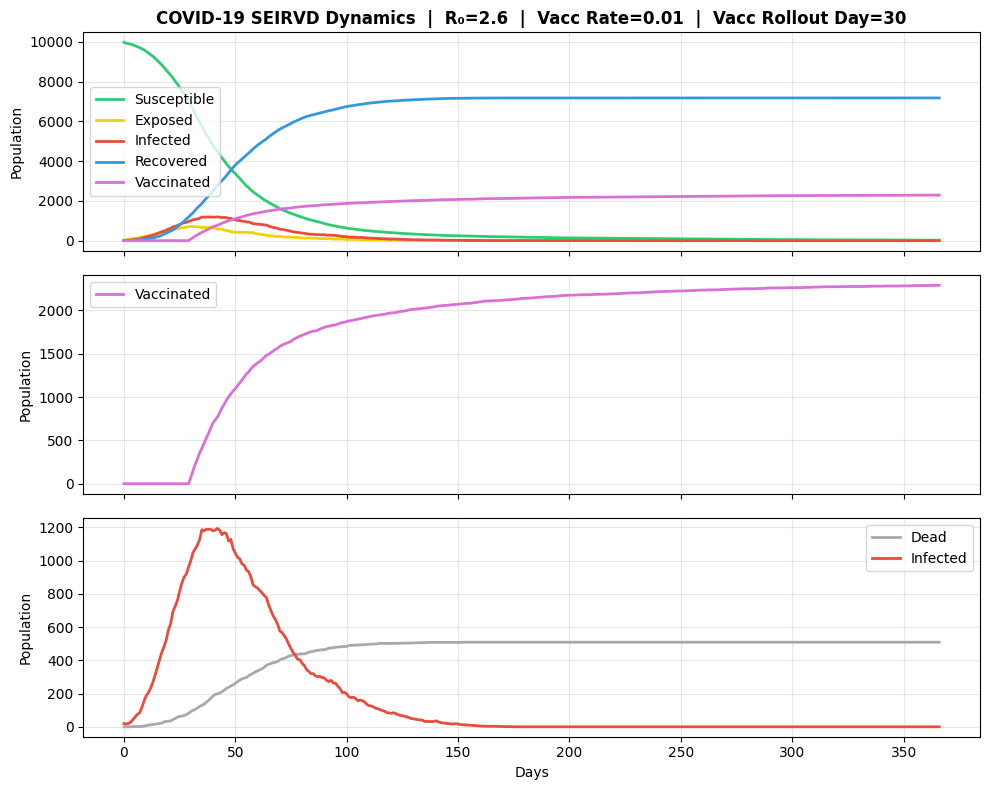

In [1]:
#Spatial plot diagrams - parameters can be changed at the bottom
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mc
from matplotlib.patches import Patch
from scipy import stats

# State values
S = 0   # Susceptible
I = 1   # Infected
R = 2   # Recovered
E = 3   # Exposed
D = 4   # Dead
V = 5   # Vaccinated

# Model parameters
R0            = 2.6
RECOVERY_RATE = 0.11
ONSET_RATE    = 1 / 4.5
CFR           = 0.00808

# Infection probabilty calculation
def compute_p_inf(R0, recovery_rate):
    # p_inf = infection rate in our model: rearranged formula for R0 = infection rate/recovery rate
    return min(R0 * recovery_rate, 1.0)  # min( , ) function prevents probability from exceeding 1.0

# Counts adjacent infected cells
def count_infected(x, i, j):
    n = len(x)
    i_start = max(0, i-1)
    i_end   = min(n, i+2)
    j_start = max(0, j-1)
    j_end   = min(n, j+2)
    sub_array = x[i_start:i_end, j_start:j_end]
    # All 9 cells (including the individual) are added to a separate array in which the total infected cells are counted
    infected  = np.sum(sub_array == I)
    if x[i, j] == I:
        infected -= 1
    # Removes the individual cell itself from the count
    return infected

# Defines the day-to-day changes in the grid
def advance(grid, n, p_inf, step, vacc_rate, vacc_days):
    result = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            # Susceptible cells
            if grid[i, j] == S:
                num_infected_neighbours = count_infected(grid, i, j)
                if step >= vacc_days and np.random.rand() < vacc_rate:
                    result[i, j] = V  # Vaccinated before exposure check
                elif num_infected_neighbours > 0:
                    successes = np.random.binomial(num_infected_neighbours, p_inf)
                    # Bernoulli trial with each infected neighbour having p_inf probability to infect
                    result[i, j] = E if successes > 0 else S  # A single success means cell = exposed
                else:
                    result[i, j] = S

            # Exposed cells
            elif grid[i, j] == E:
                if np.random.binomial(1, ONSET_RATE):  # A single Bernoulli trial with p = onset rate
                    result[i, j] = I  # Becomes infectious
                else:
                    result[i, j] = E  # Cell stays exposed if onset has not occurred

            # Infected cells
            elif grid[i, j] == I:
                if np.random.binomial(1, CFR):  # Trial to decide I->D
                    result[i, j] = D
                elif np.random.binomial(1, RECOVERY_RATE):  # Trial to decide I->R
                    result[i, j] = R
                else:
                    result[i, j] = I  # Cell stays infected if no successes in previous trials

            elif grid[i, j] == R:
                result[i, j] = R  # Recovered cells remain recovered

            elif grid[i, j] == V:
                result[i, j] = V  # Vaccinated cells remain vaccinated

            elif grid[i, j] == D:
                result[i, j] = D  # Dead cells remain dead

    return result

# Counts total cells in each state and stores values
def count_states(grid):
    return {
        'S': int(np.sum(grid == S)),
        'E': int(np.sum(grid == E)),
        'I': int(np.sum(grid == I)),
        'R': int(np.sum(grid == R)),
        'V': int(np.sum(grid == V)),
        'D': int(np.sum(grid == D))
    }


# Runs the simulation    
def run_simulation(n, steps, vacc_rate, vacc_days):
    p_inf = compute_p_inf(R0, RECOVERY_RATE)

    # Creating an nxn grid
    grid = np.zeros((n, n), dtype=int)
    # Seeding 20 different infected cells within the grid
    for _ in range(20):
        x, y      = np.random.randint(0, n, size=2)
        grid[x, y] = I

    history = {k: [] for k in ['S', 'E', 'I', 'R', 'V', 'D']}

    # Snapshots for visual models every 18 days
    snap_steps = sorted(set([0, steps//18, 2*steps//18, 3*steps//18, 4*steps//18,
                              5*steps//18, 6*steps//18, 7*steps//18, 8*steps//18, steps-1]))
    snap_grids = {}

    # Stores totals for each state in the history dictionary
    current = grid.copy()
    counts  = count_states(current)
    for k in history:
        history[k].append(counts[k])

    # Advances for each day 
    for step in range(1, steps+1):
        if step-1 in snap_steps:
            snap_grids[step-1] = current.copy()
        current = advance(current, n, p_inf, step, vacc_rate, vacc_days)
        counts  = count_states(current)
        for k in history:
            history[k].append(counts[k])

    # Colormap, position matches integer state value
    cmap = mc.ListedColormap([
        "#2ecc71",   # 0 S — green
        "#e74c3c",   # 1 I — red
        "#3498db",   # 2 R — light blue
        "#EED202",   # 3 E — yellow
        "#A9A9A9",   # 4 D — grey
        "#DA70D6",   # 5 V — orchid
    ])
    bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
    norm   = mc.BoundaryNorm(bounds, cmap.N)

    # Adding labels to the colormap
    legend_patches = [
        Patch(color='#2ecc71', label='Susceptible'),
        Patch(color='#EED202', label='Exposed'),
        Patch(color='#e74c3c', label='Infected'),
        Patch(color='#DA70D6', label='Vaccinated'),
        Patch(color='#3498db', label='Recovered'),
        Patch(color='#A9A9A9', label='Dead')
    ]

    # Figure 1: spatial model visual showcase
    num_cols = (len(snap_steps) + 1) // 2
    fig1, axes = plt.subplots(2, num_cols, figsize=(15, 7))
    axes = axes.flatten()

    fig1.suptitle(f'COVID-19 SEIRVD Spatial Model  |  R₀={R0}  |  Vacc Rate={vacc_rate}  |  Vacc Rollout Day={vacc_days}',
                  fontsize=12, fontweight='bold')

    #Showing only the grids of snapshot days
    for ax, t in zip(axes, snap_steps):
        g = snap_grids.get(t, np.zeros((n, n)))
        ax.imshow(g, cmap=cmap, norm=norm, interpolation='nearest')
        ax.set_title(f't = {t}', fontsize=10)
        ax.axis('off')

    for ax in axes[len(snap_steps):]:
        ax.axis('off')

    fig1.legend(handles=legend_patches, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.05))
    fig1.tight_layout()
    fig1.savefig(f'seirvd_snapshots_vacc{vacc_rate}_day{vacc_days}.png', dpi=150, bbox_inches='tight')

    # Figure 2: graph of states during the days of the investigation (same x-axis)
    t_axis = np.arange(steps+1)
    fig2, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

    # First graph shows the number of cells in each state over the whole investigations
    ax1.plot(t_axis, history['S'], color='#2ecc71', lw=2, label='Susceptible')
    ax1.plot(t_axis, history['E'], color='#EED202', lw=2, label='Exposed')
    ax1.plot(t_axis, history['I'], color='#e74c3c', lw=2, label='Infected')
    ax1.plot(t_axis, history['R'], color='#3498db', lw=2, label='Recovered')
    ax1.plot(t_axis, history['V'], color='#DA70D6', lw=2, label='Vaccinated')
    ax1.set_ylabel('Population')
    ax1.set_title(f'COVID-19 SEIRVD Dynamics  |  R₀={R0}  |  Vacc Rate={vacc_rate}  |  Vacc Rollout Day={vacc_days}',
                  fontsize=12, fontweight='bold')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Second graph only shows the number of vaccinated individuals during the investigation
    ax2.plot(t_axis, history['V'], color='#DA70D6', lw=2, label='Vaccinated')
    ax2.set_ylabel('Population')
    ax2.legend()
    ax2.grid(alpha=0.3)

    # Third graph shows dead and infected over the course of the investigation
    ax3.plot(t_axis, history['D'], color='#A9A9A9', lw=2, label='Dead')
    ax3.plot(t_axis, history['I'], color='#e74c3c', lw=2, label='Infected')
    ax3.set_xlabel('Days')
    ax3.set_ylabel('Population')
    ax3.legend()
    ax3.grid(alpha=0.3)

    fig2.tight_layout()
    fig2.savefig(f'seirvd_timeseries_vacc{vacc_rate}_day{vacc_days}.png', dpi=150, bbox_inches='tight')
    plt.show()

# Simulation running on a 100*100 grid for 366 days with a 1% daily vaccination rate and a vaccination rollout of 30 days
run_simulation(n=100, steps=366, vacc_rate=0.01, vacc_days=30)

───────────────────────────────────────────────────────────────────────────────────────────────
 Vacc Rate     Peak Inf (mean±std)         Total Inf (mean±std)      Total Deaths (mean±std)
───────────────────────────────────────────────────────────────────────────────────────────────
      0.00        1255 ± 86              9999 ± 1                687 ± 25      
      0.01        1254 ± 59              7998 ± 220              539 ± 30      
      0.02        1166 ± 78              6373 ± 427              435 ± 28      
      0.03        1108 ± 79              5395 ± 348              370 ± 31      
      0.04        1126 ± 80              4986 ± 280              342 ± 32      
      0.05        1105 ± 117             4692 ± 427              311 ± 24      
      0.06        1062 ± 79              4361 ± 278              298 ± 26      
      0.07        1031 ± 103             4093 ± 364              283 ± 33      
      0.08        1037 ± 74              3987 ± 233              276 ± 23  

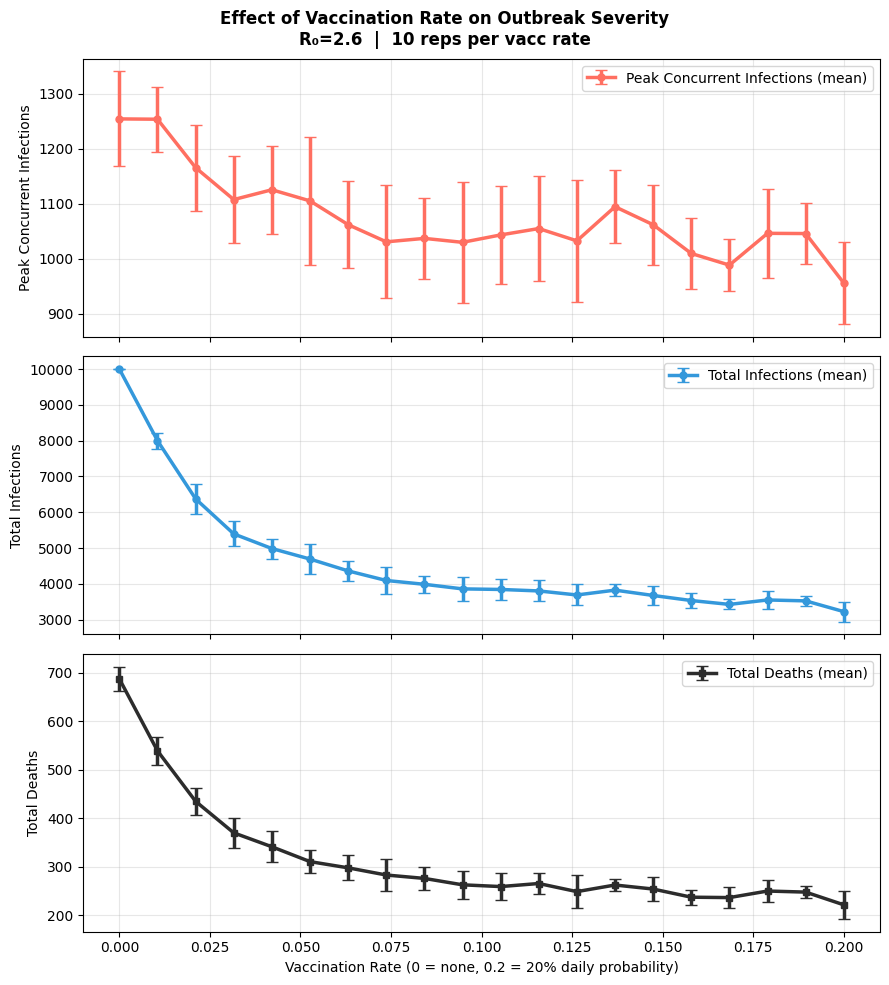

In [1]:
#Shorter version of vaccination rate sweep
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mc
from matplotlib.patches import Patch
from scipy import stats

# State values
S = 0 # Susceptible
I = 1 # Infected
R = 2 # Recovered
E = 3 # Exposed
D = 4 # Dead
V = 5 # Vaccinated

# Model Parameters
R0 = 2.6
RECOVERY_RATE = 0.11
ONSET_RATE = 1 / 4.5
CFR = 0.00808

# Probability of infection calculation
def compute_p_inf(R0, recovery_rate):
    # p_inf = infection rate in our model: rearranged formula for R0 = infection rate/recovery rate
    return min(R0 * recovery_rate, 1.0)  # min( , ) function prevents probability from exceeding 1.0


# Counts the number of adjacent infected cells
def count_infected(x, i, j):
    n = len(x)
    i_start = max(0, i-1)
    i_end   = min(n, i+2)
    j_start = max(0, j-1)
    j_end   = min(n, j+2)
    sub_array = x[i_start:i_end, j_start:j_end]
    # All 9 cells (including the individual) are added to a separate array in which the total infected cells are counted
    infected  = np.sum(sub_array == I)
    if x[i, j] == I:
        infected -= 1
    # Removes the individual cell itself from the count
    return infected


# Defines the day-to-day changes in the grid
def advance(grid, n, p_inf, step, vacc_rate, vacc_days):
    result = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            # Susceptible cells
            if grid[i, j] == S:
                num_infected_neighbours = count_infected(grid, i, j)
                if step >= vacc_days and np.random.rand() < vacc_rate:
                    result[i, j] = V  # Vaccinated before exposure check
                elif num_infected_neighbours > 0:
                    successes = np.random.binomial(num_infected_neighbours, p_inf)
                    # Bernoulli trial with each infected neighbour having p_inf probability to infect
                    result[i, j] = E if successes > 0 else S  # A single success means cell = exposed
                else:
                    result[i, j] = S

            # Exposed cells
            elif grid[i, j] == E:
                if np.random.binomial(1, ONSET_RATE):  # A single Bernoulli trial with p = onset rate
                    result[i, j] = I  # Becomes infectious
                else:
                    result[i, j] = E  # Cell stays exposed if onset has not occurred

            # Infected cells
            elif grid[i, j] == I:
                if np.random.binomial(1, CFR):  # Trial to decide I->D
                    result[i, j] = D
                elif np.random.binomial(1, RECOVERY_RATE):  # Trial to decide I->R
                    result[i, j] = R
                else:
                    result[i, j] = I  # Cell stays infected if no successes in previous trials

            elif grid[i, j] == R:
                result[i, j] = R  # Recovered cells remain recovered

            elif grid[i, j] == V:
                result[i, j] = V  # Vaccinated cells remain vaccinated

            elif grid[i, j] == D:
                result[i, j] = D  # Dead cells remain dead

    return result


# Finds the peak concurrent infections, total infections and deaths (summary statistics) in a simulation
def run_simulation_metrics(n, steps, vacc_rate, vacc_days):
    p_inf = compute_p_inf(R0, RECOVERY_RATE)
    grid = np.zeros((n, n), dtype=int)
    # Multincleate seeding
    for _ in range(20):
        x, y = np.random.randint(0, n, size=2)
        grid[x, y] = I

    peak_I = 0
    current = grid.copy()
    for step in range(steps):
        n_infected = int(np.sum(current == I))
        if n_infected > peak_I:
            peak_I = n_infected
        current = advance(current, n, p_inf, step, vacc_rate, vacc_days)
    # Total infections = all cells that have passed through I 
    total_I = int(np.sum(current == R)) + int(np.sum(current == D))
    total_D = int(np.sum(current == D))
    return peak_I, total_I, total_D


# Running the simulation, defining the range of vaccination rates to test and number of samples
def vaccine_rate_sweep(n=100, steps=200, repeats=10):   
    vacc_rates = np.linspace(0, 0.2, 20) 
    # Store mean and standard deviation of each metric across repeats
    mean_peaks,  std_peaks  = [], []
    mean_totals, std_totals = [], []
    mean_deaths, std_deaths = [], []
    # Table header
    print(f"{'─'*95}")
    print(f"{'Vacc Rate':>10}  {'Peak Inf (mean±std)':>22}  {'Total Inf (mean±std)':>27}  {'Total Deaths (mean±std)':>27}")
    print(f"{'─'*95}")

     # Store results from repeats per vaccination rate
    for rate in vacc_rates:
        run_peaks, run_totals, run_deaths = [], [], []

        # Finding the summary statistics
        for _ in range(repeats):
            peak, total, deaths = run_simulation_metrics(n, steps, vacc_rate=rate, vacc_days=30)
            run_peaks.append(peak)
            run_totals.append(total)
            run_deaths.append(deaths)

        # Calculating mean and standard deviation across repeats for all states
        mp, sp = np.mean(run_peaks),  np.std(run_peaks)
        mt, st = np.mean(run_totals), np.std(run_totals)
        md, sd = np.mean(run_deaths), np.std(run_deaths)

        mean_peaks.append(mp);  std_peaks.append(sp)
        mean_totals.append(mt); std_totals.append(st)
        mean_deaths.append(md); std_deaths.append(sd)

        print(f"{rate:>10.2f}  {mp:>10.0f} ± {sp:<8.0f}  {mt:>10.0f} ± {st:<8.0f}  {md:>10.0f} ± {sd:<8.0f}")

    print(f"{'─'*95}")

    # Calculating Spearman's rank correlation for vaccination rate against summary stats
    rho_i, p_i = stats.spearmanr(vacc_rates, mean_peaks)
    rho_t, p_t = stats.spearmanr(vacc_rates, mean_totals)
    rho_d, p_d = stats.spearmanr(vacc_rates, mean_deaths)
    print(f"\nSpearman correlation — Peak Infections:  r={rho_i:.3f}, p={p_i:.4f}")
    print(f"Spearman correlation — Total Infections: r={rho_t:.3f}, p={p_t:.4f}")
    print(f"Spearman correlation — Total Deaths:     r={rho_d:.3f}, p={p_d:.4f}")

     # Changing lists to NumPy arrays
    mean_peaks  = np.array(mean_peaks)
    std_peaks   = np.array(std_peaks)
    mean_totals = np.array(mean_totals)
    std_totals  = np.array(std_totals)
    mean_deaths = np.array(mean_deaths)
    std_deaths  = np.array(std_deaths)

    # Producing comparitive graphs for the summary statistics against vaccination rate (same x-axis of vaccination rate), averaged over all repeats for values of vaccination rate 
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
    fig.suptitle(
        f'Effect of Vaccination Rate on Outbreak Severity\n'
        f'R₀={R0}  |  {repeats} reps per vacc rate', fontsize=12, fontweight='bold')

    # First graph shows the highest number of infections at one time 
    ax1.errorbar(vacc_rates, mean_peaks, yerr=std_peaks, color='#FF6F61',
                 lw=2.5, marker='o', markersize=5, capsize=4, label='Peak Concurrent Infections (mean)')
    ax1.set_ylabel('Peak Concurrent Infections')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Second graph shows the total infections 
    ax2.errorbar(vacc_rates, mean_totals, yerr=std_totals, color='#3498db',
                 lw=2.5, marker='o', markersize=5, capsize=4, label='Total Infections (mean)')
    ax2.set_ylabel('Total Infections')
    ax2.legend()
    ax2.grid(alpha=0.3)

    #Third graph shows the total deaths 
    ax3.errorbar(vacc_rates, mean_deaths, yerr=std_deaths, color='#2c2c2c',
                 lw=2.5, marker='s', markersize=5, capsize=4, label='Total Deaths (mean)')
    ax3.set_ylabel('Total Deaths')
    ax3.set_xlabel('Vaccination Rate (0 = none, 0.2 = 20% daily probability)')
    ax3.legend()
    ax3.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('vaccine_sweep.png', dpi=150, bbox_inches='tight')
    plt.show()

    return vacc_rates, mean_peaks, std_peaks, mean_totals, std_totals, mean_deaths, std_deaths


rates, mean_peaks_rate, std_peaks_rate, mean_totals_rate, std_totals_rate, mean_deaths_rate, std_deaths_rate = vaccine_rate_sweep()

Vacc rate 0.000 done
Vacc rate 0.011 done
Vacc rate 0.021 done
Vacc rate 0.032 done
Vacc rate 0.042 done
Vacc rate 0.053 done
Vacc rate 0.063 done
Vacc rate 0.074 done
Vacc rate 0.084 done
Vacc rate 0.095 done
Vacc rate 0.105 done
Vacc rate 0.116 done
Vacc rate 0.126 done
Vacc rate 0.137 done
Vacc rate 0.147 done
Vacc rate 0.158 done
Vacc rate 0.168 done
Vacc rate 0.179 done
Vacc rate 0.189 done
Vacc rate 0.200 done
Saved 200 runs to vaccine_sweep_runs.npz

───────────────────────────────────────────────────────────────────────────────────────────────
Peak Concurrent Infections
───────────────────────────────────────────────────────────────────────────────────────────────
Model                NLL         AIC      ΔAIC  Parameters
Exponential      1183.45     2374.91      0.00  A=320.4, k=51.52, C=1036, dispersion=163.5
Hyperbolic       1183.95     2375.90      0.99  A=362.2, k=84.58, C=1005, dispersion=162.5
Logistic         1183.99     2377.98      3.07  A=623, k=74.93, r50=1.547e-106

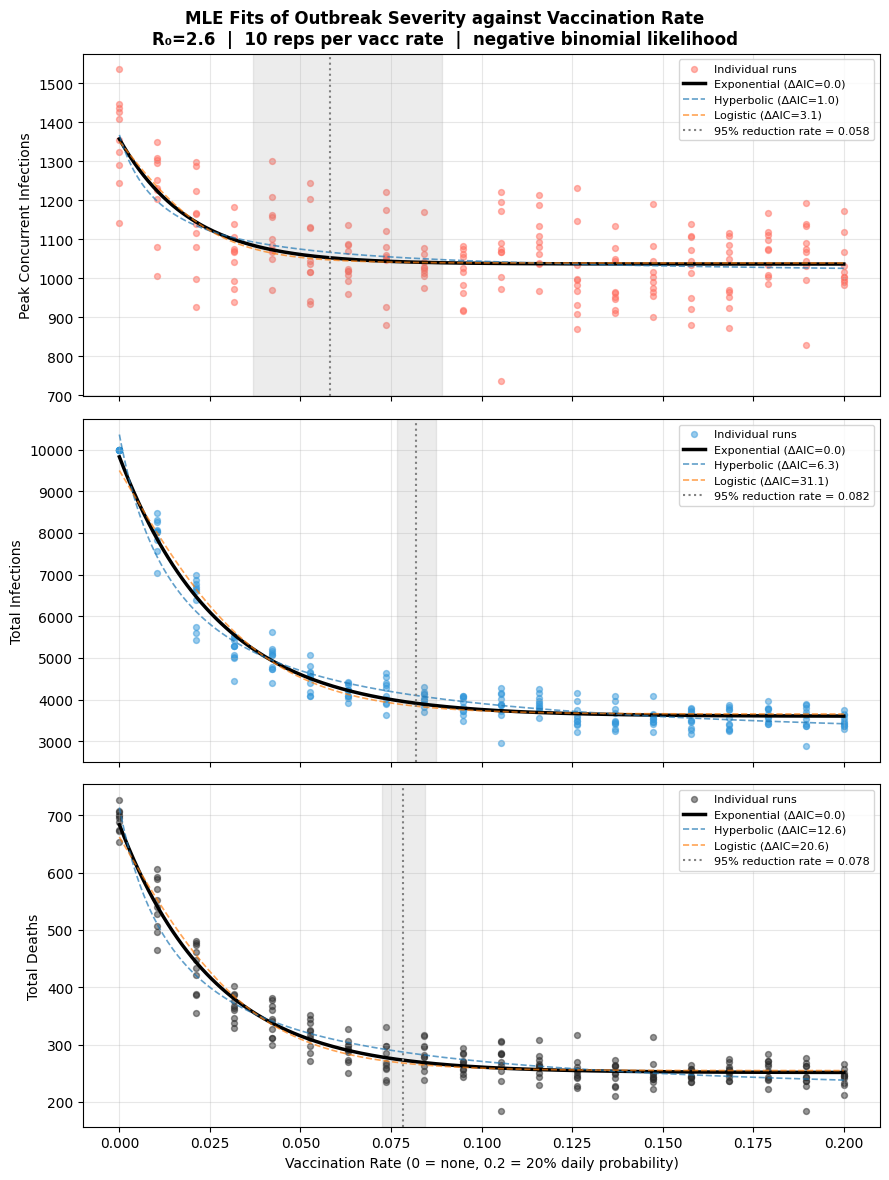

In [9]:
# MLE fit of outbreak severity against vaccination rate
# Needs the vaccination rate sweep cell to have been run first (uses run_simulation_metrics from it)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, brentq
from scipy.special import expit

# Sweep settings, matching the vaccination rate sweep cell
MLE_VACC_RATES = np.linspace(0, 0.2, 20)
MLE_REPEATS    = 10
MLE_VACC_DAYS  = 30
MLE_N          = 100
MLE_STEPS      = 200
RUNS_FILE      = 'vaccine_sweep_runs.npz'   # raw runs are saved here so the slow sweep only has to run once


# Runs the sweep but keeps every individual run (the sweep cell only keeps mean and std)
# Data collection
def collect_sweep_runs(n=MLE_N, steps=MLE_STEPS):
    all_rates, all_peaks, all_totals, all_deaths = [], [], [], []
    for rate in MLE_VACC_RATES:
        for _ in range(MLE_REPEATS):
            peak, total, deaths = run_simulation_metrics(n, steps, vacc_rate=rate, vacc_days=MLE_VACC_DAYS)
            all_rates.append(rate)
            all_peaks.append(peak)
            all_totals.append(total)
            all_deaths.append(deaths)
        print(f"Vacc rate {rate:.3f} done")
    return np.array(all_rates), np.array(all_peaks), np.array(all_totals), np.array(all_deaths)


# Candidate curves for the mean outcome against vaccination rate, all falling from C + A towards a floor C
# Creating equations
def exp_decay(r, A, k, C):
    return C + A * np.exp(-k * r)

def hyperbolic(r, A, k, C):
    return C + A / (1 + k * r)

def logistic(r, A, k, r50, C):
    return C + A * expit(-k * (r - r50))

# Model name: (curve, parameter names)
MODELS = {
    'Exponential': (exp_decay,  ['A', 'k', 'C']),
    'Hyperbolic':  (hyperbolic, ['A', 'k', 'C']),
    'Logistic':    (logistic,   ['A', 'k', 'r50', 'C']),
}


# Negative log-likelihood of the runs given a curve
# Outcomes are counts that vary more between repeats than a Poisson allows, so a negative binomial is used
# Parameters are fitted on a log scale to keep them positive; the last parameter is the negative binomial dispersion
def neg_log_lik(log_params, curve, x, y):
    params = np.exp(log_params)
    mu     = np.clip(curve(x, *params[:-1]), 1e-9, None)
    size   = params[-1]
    return -np.sum(stats.nbinom.logpmf(y, size, size / (size + mu)))


# Finds the maximum likelihood parameters, trying several starting points so the optimiser does not get stuck
def fit_model(curve, starts, x, y):
    best = None
    for x0 in starts:
        res = minimize(neg_log_lik, np.log(x0), args=(curve, x, y), method='Nelder-Mead',
                       options={'maxiter': 20000, 'maxfev': 20000, 'xatol': 1e-6, 'fatol': 1e-6})
        if best is None or res.fun < best.fun:
            best = res
    return np.exp(best.x), best.fun


# Starting guesses for each model from the data
def starting_points(name, x, y):
    y_hi = np.mean(y[x == x.min()])
    y_lo = np.mean(y[x == x.max()])
    A0, C0, size0 = max(y_hi - y_lo, 1.0), max(y_lo, 0.5), 10.0
    if name == 'Logistic':
        return [[A0, k0, r50, C0, size0] for k0 in (20, 50, 150) for r50 in (0.02, 0.05, 0.1)]
    return [[A0, k0, C0, size0] for k0 in (5, 20, 50, 150)]


# Vaccination rate that achieves 95% of the reduction the curve can give (curve - C falls to 5% of its value at rate 0)
def rate_95(curve, params):
    C = params[-1]
    target = 0.05 * (curve(0.0, *params) - C)
    return brentq(lambda r: curve(r, *params) - C - target, 0.0, 100.0)


# Bootstrap: resample runs within each vaccination rate, refit, and recompute the 95% rate
def bootstrap_rate_95(curve, mle_params, x, y, n_boot=300):
    rng = np.random.default_rng()
    groups = [np.where(x == r)[0] for r in np.unique(x)]
    boot = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
        params, _ = fit_model(curve, [mle_params], x[idx], y[idx])
        boot.append(rate_95(curve, params[:-1]))
    return np.percentile(boot, [2.5, 97.5])


# Fits all models to one outcome, prints the AIC table and the 95% rate, and plots the fits
def analyse_outcome(label, x, y, ax, colour):
    print(f"\n{'─'*95}\n{label}\n{'─'*95}")
    fits = {}
    for name, (curve, names) in MODELS.items():
        params, nll = fit_model(curve, starting_points(name, x, y), x, y)
        p = len(params)  # curve parameters + dispersion
        fits[name] = {'params': params, 'NLL': nll, 'AIC': 2*p + 2*nll}

    best_name = min(fits, key=lambda m: fits[m]['AIC'])
    best_aic  = fits[best_name]['AIC']
    print(f"{'Model':<12}  {'NLL':>10}  {'AIC':>10}  {'ΔAIC':>8}  Parameters")
    for name, f in sorted(fits.items(), key=lambda kv: kv[1]['AIC']):
        names = MODELS[name][1] + ['dispersion']
        param_str = ', '.join(f"{n}={v:.4g}" for n, v in zip(names, f['params']))
        print(f"{name:<12}  {f['NLL']:>10.2f}  {f['AIC']:>10.2f}  {f['AIC']-best_aic:>8.2f}  {param_str}")

    curve = MODELS[best_name][0]
    mle_params = fits[best_name]['params']
    r95 = rate_95(curve, mle_params[:-1])
    ci_lo, ci_hi = bootstrap_rate_95(curve, mle_params, x, y)
    print(f"\nBest model: {best_name}")
    print(f"Vaccination rate for 95% of the achievable reduction: {r95:.4f}  (95% CI {ci_lo:.4f} – {ci_hi:.4f})")
    if r95 > x.max():
        print("Note: this is beyond the tested range of vaccination rates, so it is an extrapolation")

    # Plot raw runs, all fitted curves (best one solid) and the 95% rate with its confidence interval
    r_grid = np.linspace(0, x.max(), 300)
    ax.scatter(x, y, s=18, alpha=0.5, color=colour, label='Individual runs')
    for name, f in fits.items():
        style = dict(lw=2.5, ls='-', color='black') if name == best_name else dict(lw=1.2, ls='--', alpha=0.7)
        ax.plot(r_grid, MODELS[name][0](r_grid, *f['params'][:-1]), label=f"{name} (ΔAIC={f['AIC']-best_aic:.1f})", **style)
    ax.axvline(r95, color='grey', ls=':', lw=1.5, label=f'95% reduction rate = {r95:.3f}')
    ax.axvspan(ci_lo, ci_hi, color='grey', alpha=0.15)
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    return fits, best_name, r95, (ci_lo, ci_hi)


# Load saved runs if they exist and match the current settings, otherwise run the sweep (slow) and save them
settings = np.array([MLE_REPEATS, MLE_VACC_DAYS, MLE_N, MLE_STEPS])
data = np.load(RUNS_FILE) if os.path.exists(RUNS_FILE) else None
if (data is not None and 'peaks' in data.files and np.array_equal(data['settings'], settings)
        and np.array_equal(np.unique(data['rates']), MLE_VACC_RATES)):
    mle_rates, mle_peaks, mle_totals, mle_deaths = data['rates'], data['peaks'], data['totals'], data['deaths']
    print(f"Loaded {len(mle_rates)} runs from {RUNS_FILE}")
else:
    mle_rates, mle_peaks, mle_totals, mle_deaths = collect_sweep_runs()
    np.savez(RUNS_FILE, rates=mle_rates, peaks=mle_peaks, totals=mle_totals, deaths=mle_deaths, settings=settings)
    print(f"Saved {len(mle_rates)} runs to {RUNS_FILE}")

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 12), sharex=True)
fig.suptitle(f'MLE Fits of Outbreak Severity against Vaccination Rate\n'
             f'R₀={R0}  |  {MLE_REPEATS} reps per vacc rate  |  negative binomial likelihood',
             fontsize=12, fontweight='bold')

fits_peaks,  best_peaks,  r95_peaks,  ci_peaks  = analyse_outcome('Peak Concurrent Infections', mle_rates, mle_peaks,  ax1, '#FF6F61')
fits_totals, best_totals, r95_totals, ci_totals = analyse_outcome('Total Infections',           mle_rates, mle_totals, ax2, '#3498db')
fits_deaths, best_deaths, r95_deaths, ci_deaths = analyse_outcome('Total Deaths',               mle_rates, mle_deaths, ax3, '#2c2c2c')
ax3.set_xlabel('Vaccination Rate (0 = none, 0.2 = 20% daily probability)')

plt.tight_layout()
plt.savefig('vaccine_sweep_mle.png', dpi=150, bbox_inches='tight')
plt.show()

───────────────────────────────────────────────────────────────────────────────────────────────
Rollout Day     Peak Inf (mean±std)    Total Inf (mean±std)    Total Deaths (mean±std)
───────────────────────────────────────────────────────────────────────────────────────────────
         0         722 ± 36              4878 ± 129              333 ± 25      
         4         785 ± 85              5500 ± 340              367 ± 28      
         8         857 ± 87              5977 ± 358              427 ± 16      
        12         990 ± 50              6658 ± 176              452 ± 25      
        16         994 ± 50              6851 ± 183              470 ± 19      
        20        1073 ± 35              7183 ± 176              493 ± 22      
        24        1062 ± 124             7351 ± 440              522 ± 39      
        28        1198 ± 55              7793 ± 330              504 ± 12      
        32        1168 ± 71              7962 ± 266              550 ± 32      
 

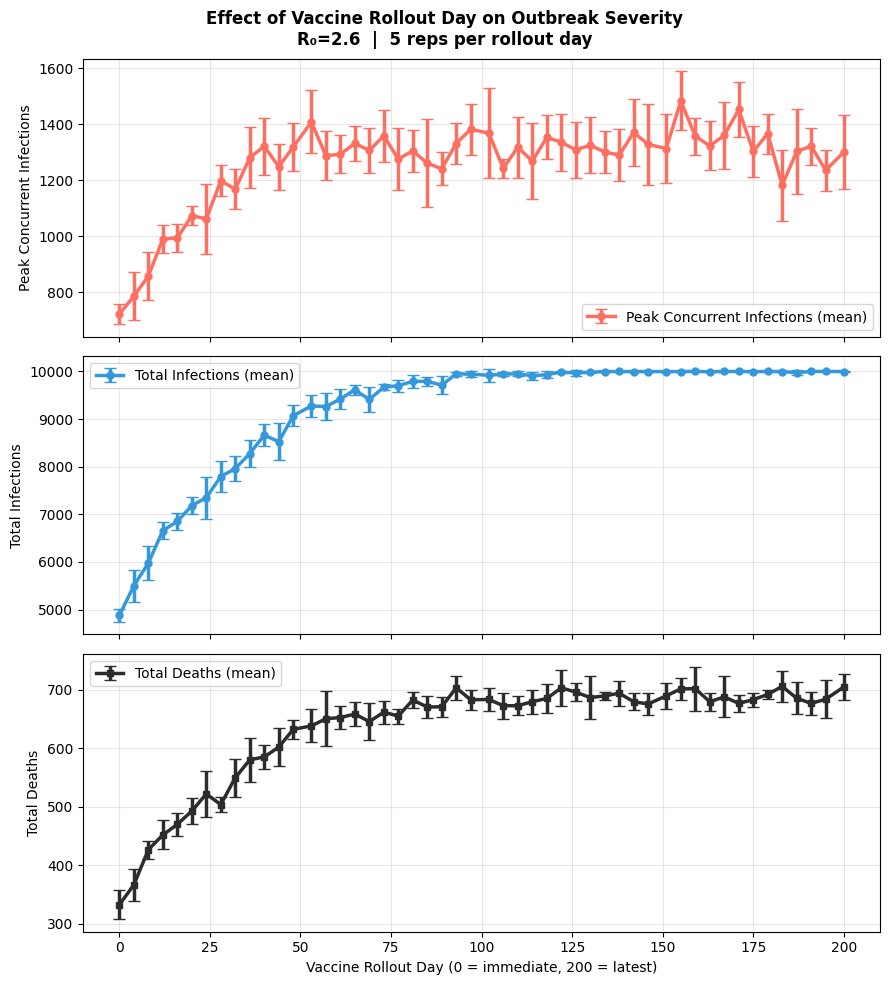

In [ ]:
#short version code for vacc rollout day sweep
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mc
from matplotlib.patches import Patch
from scipy import stats

# State values
S = 0 # Susceptible
I = 1 # Infected
R = 2 # Recovered
E = 3 # Exposed
D = 4 # Dead
V = 5 # Vaccinated

# Model parameters
R0 = 2.6
RECOVERY_RATE = 0.11
ONSET_RATE = 1 / 4.5
CFR = 0.00808


# Probability of infection calculation
def compute_p_inf(R0, recovery_rate):
    # p_inf = infection rate in our model: rearranged formula for R0 = infection rate/recovery rate
    return min(R0 * recovery_rate, 1.0) # prevents p>1


# Counts the number of adjacent infected cells
def count_infected(x, i, j):
    n = len(x)
    i_start = max(0, i-1)
    i_end   = min(n, i+2)
    j_start = max(0, j-1)
    j_end   = min(n, j+2)
    sub_array = x[i_start:i_end, j_start:j_end]
    # All 9 cells (including the individual) are added to a separate array in which the total infected cells are counted
    infected  = np.sum(sub_array == I)
    if x[i, j] == I:
        infected -= 1
    # Removes the individual cell itself from the count
    return infected


# Defines the day-to-day changes in the grid
def advance(grid, n, p_inf, step, vacc_rate, vacc_days):
    result = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            # Susceptible cells
            if grid[i, j] == S:
                num_infected_neighbours = count_infected(grid, i, j)
                if step >= vacc_days and np.random.rand() < vacc_rate:
                    result[i, j] = V  # Vaccinated before exposure check
                elif num_infected_neighbours > 0:
                    successes = np.random.binomial(num_infected_neighbours, p_inf)
                    # Bernoulli trial with each infected neighbour having p_inf probability to infect
                    result[i, j] = E if successes > 0 else S  # A single success means cell = exposed
                else:
                    result[i, j] = S

            # Exposed cells
            elif grid[i, j] == E:
                if np.random.binomial(1, ONSET_RATE):  # A single Bernoulli trial with p = onset rate
                    result[i, j] = I  # Becomes infectious
                else:
                    result[i, j] = E  # Cell stays exposed if onset has not occurred

            # Infected cells
            elif grid[i, j] == I:
                if np.random.binomial(1, CFR):  # Trial to decide I->D
                    result[i, j] = D
                elif np.random.binomial(1, RECOVERY_RATE):  # Trial to decide I->R
                    result[i, j] = R
                else:
                    result[i, j] = I  # Cell stays infected if no successes in previous trials

            elif grid[i, j] == R:
                result[i, j] = R  # Recovered cells remain recovered

            elif grid[i, j] == V:
                result[i, j] = V  # Vaccinated cells remain vaccinated

            elif grid[i, j] == D:
                result[i, j] = D  # Dead cells remain dead

    return result

# Finds the peak concurrent infections, total infections + deaths (summary statistics) in a simulation
def run_simulation_metrics(n, steps, vacc_rate, vacc_days):
    p_inf = compute_p_inf(R0, RECOVERY_RATE)
    grid = np.zeros((n, n), dtype=int)
    # Multincleate seeding
    for _ in range(20):
        x, y = np.random.randint(0, n, size=2)
        grid[x, y] = I

    # Check if current total infected > peak
    peak_I = 0
    current = grid.copy()
    for step in range(steps):
        n_infected = int(np.sum(current == I))
        if n_infected > peak_I:
            peak_I = n_infected
        current = advance(current, n, p_inf, step, vacc_rate, vacc_days)
    # Total infections = all cells that have passed through I 
    total_I = int(np.sum(current == R)) + int(np.sum(current == D))
    total_D = int(np.sum(current == D))
    return peak_I, total_I, total_D

# Runs simulations to find the summary stats over multiple repeats (stochastic simulation)
def vaccine_rollout_sweep(n=100, steps=200, repeats=5):
    # Deciding rollout days 
    rollout_days = np.linspace(0, 200, 50, dtype=int)
    mean_peaks,  std_peaks  = [], []
    mean_totals, std_totals = [], []
    mean_deaths, std_deaths = [], []

    # Table with all summary stats for rollout days
    print(f"{'─'*95}")
    print(f"{'Rollout Day':>10}  {'Peak Inf (mean±std)':>22}  {'Total Inf (mean±std)':>22}  {'Total Deaths (mean±std)':>25}")
    print(f"{'─'*95}")

    for day in rollout_days:
        run_peaks, run_totals, run_deaths = [], [], []

        # Finding summary statistics
        for _ in range(repeats):
            peak, total, deaths = run_simulation_metrics(n, steps, vacc_rate=0.01, vacc_days=day)
            run_peaks.append(peak)
            run_totals.append(total)
            run_deaths.append(deaths)

        mp, sp = np.mean(run_peaks),  np.std(run_peaks)
        mt, st = np.mean(run_totals), np.std(run_totals)
        md, sd = np.mean(run_deaths), np.std(run_deaths)

        mean_peaks.append(mp);  std_peaks.append(sp)
        mean_totals.append(mt); std_totals.append(st)
        mean_deaths.append(md); std_deaths.append(sd)

        print(f"{day:>10}  {mp:>10.0f} ± {sp:<8.0f}  {mt:>10.0f} ± {st:<8.0f}  {md:>10.0f} ± {sd:<8.0f}")

    print(f"{'─'*95}")
    
    # Finding Spearman's rank correlation for the summay statistics
    rho_i, p_i = stats.spearmanr(rollout_days, mean_peaks)
    rho_t, p_t = stats.spearmanr(rollout_days, mean_totals)
    rho_d, p_d = stats.spearmanr(rollout_days, mean_deaths)
    print(f"\nSpearman correlation — Peak Infections:  r={rho_i:.3f}, p={p_i:.4f}")
    print(f"Spearman correlation — Total Infections: r={rho_t:.3f}, p={p_t:.4f}")
    print(f"Spearman correlation — Total Deaths:     r={rho_d:.3f}, p={p_d:.4f}")

    # Storing summary statistics for each repeat
    mean_peaks  = np.array(mean_peaks)
    std_peaks   = np.array(std_peaks)
    mean_totals = np.array(mean_totals)
    std_totals  = np.array(std_totals)
    mean_deaths = np.array(mean_deaths)
    std_deaths  = np.array(std_deaths)

    # Graphs showing summary statisics on the same x-axis (vaccine rollout day), taking the mean of all repeats for the value of rollout day
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
    fig.suptitle(
        f'Effect of Vaccine Rollout Day on Outbreak Severity\n'
        f'R₀={R0}  |  {repeats} reps per rollout day', fontsize=12, fontweight='bold')

    # First graph shows highest number of infections at one time 
    ax1.errorbar(rollout_days, mean_peaks, yerr=std_peaks, color='#FF6F61',
                 lw=2.5, marker='o', markersize=5, capsize=4, label='Peak Concurrent Infections (mean)')
    ax1.set_ylabel('Peak Concurrent Infections')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Second graph shows the total number of infections 
    ax2.errorbar(rollout_days, mean_totals, yerr=std_totals, color='#3498db',
                 lw=2.5, marker='o', markersize=5, capsize=4, label='Total Infections (mean)')
    ax2.set_ylabel('Total Infections')
    ax2.legend()
    ax2.grid(alpha=0.3)

    # Third graph shows the total number of deaths
    ax3.errorbar(rollout_days, mean_deaths, yerr=std_deaths, color='#2c2c2c',
                 lw=2.5, marker='s', markersize=5, capsize=4, label='Total Deaths (mean)')
    ax3.set_ylabel('Total Deaths')
    ax3.set_xlabel('Vaccine Rollout Day (0 = immediate, 200 = latest)')
    ax3.legend()
    ax3.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('vaccine_rollout_sweep.png', dpi=150, bbox_inches='tight')
    plt.show()

    return rollout_days, mean_peaks, std_peaks, mean_totals, std_totals, mean_deaths, std_deaths


rollout_days, mean_peaks_rollout, std_peaks_rollout, mean_totals_rollout, std_totals_rollout, mean_deaths_rollout, std_deaths_rollout = vaccine_rollout_sweep()

Rollout day 0 done
Rollout day 4 done
Rollout day 8 done
Rollout day 12 done
Rollout day 16 done
Rollout day 20 done
Rollout day 24 done
Rollout day 28 done
Rollout day 32 done
Rollout day 36 done
Rollout day 40 done
Rollout day 44 done
Rollout day 48 done
Rollout day 53 done
Rollout day 57 done
Rollout day 61 done
Rollout day 65 done
Rollout day 69 done
Rollout day 73 done
Rollout day 77 done
Rollout day 81 done
Rollout day 85 done
Rollout day 89 done
Rollout day 93 done
Rollout day 97 done
Rollout day 102 done
Rollout day 106 done
Rollout day 110 done
Rollout day 114 done
Rollout day 118 done
Rollout day 122 done
Rollout day 126 done
Rollout day 130 done
Rollout day 134 done
Rollout day 138 done
Rollout day 142 done
Rollout day 146 done
Rollout day 151 done
Rollout day 155 done
Rollout day 159 done
Rollout day 163 done
Rollout day 167 done
Rollout day 171 done
Rollout day 175 done
Rollout day 179 done
Rollout day 183 done
Rollout day 187 done
Rollout day 191 done
Rollout day 195 done

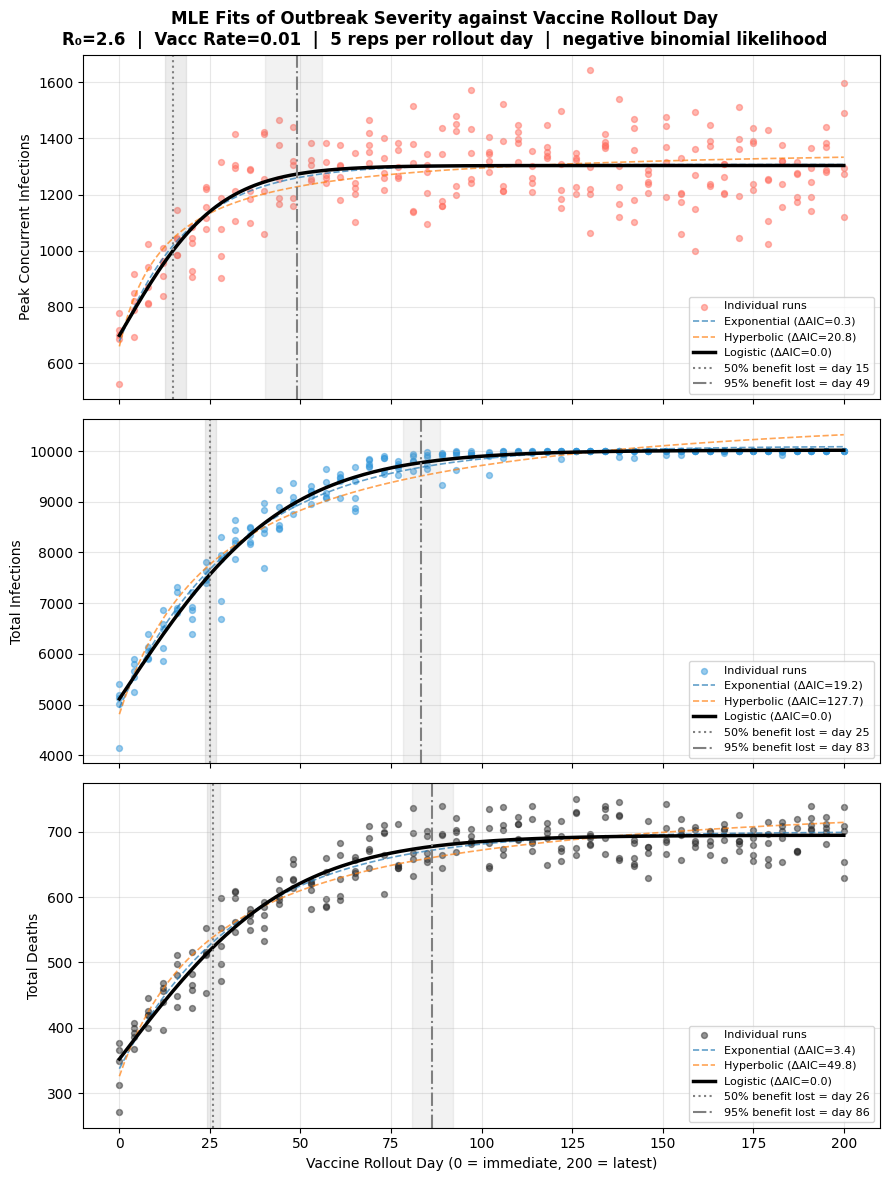

In [ ]:
# MLE fit of outbreak severity against vaccine rollout day
# Needs the vaccine rollout day sweep cell to have been run first (uses run_simulation_metrics from it)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize, brentq
from scipy.special import expit

# Sweep settings, matching the vaccine rollout day sweep cell
ROLLOUT_DAYS      = np.linspace(0, 200, 50, dtype=int)
ROLLOUT_REPEATS   = 5
ROLLOUT_VACC_RATE = 0.01
ROLLOUT_N         = 100
ROLLOUT_STEPS     = 200
ROLLOUT_RUNS_FILE = 'vaccine_rollout_runs.npz'   # raw runs are saved here so the slow sweep only has to run once


# Runs the sweep but keeps every individual run (the sweep cell only keeps mean and std)
# Data collection
def collect_rollout_runs(n=ROLLOUT_N, steps=ROLLOUT_STEPS):
    all_days, all_peaks, all_totals, all_deaths = [], [], [], []
    for day in ROLLOUT_DAYS:
        for _ in range(ROLLOUT_REPEATS):
            peak, total, deaths = run_simulation_metrics(n, steps, vacc_rate=ROLLOUT_VACC_RATE, vacc_days=day)
            all_days.append(day)
            all_peaks.append(peak)
            all_totals.append(total)
            all_deaths.append(deaths)
        print(f"Rollout day {day} done")
    return np.array(all_days, dtype=float), np.array(all_peaks), np.array(all_totals), np.array(all_deaths)


# Candidate curves for the mean outcome against rollout day, all rising towards a plateau C + A
# (the plateau is the outcome when vaccination comes too late to make any difference)
# Creating equations
def exp_saturation(d, A, k, C):
    return C + A * (1 - np.exp(-k * d))

def hyperbolic_saturation(d, A, k, C):
    return C + A * k * d / (1 + k * d)

def logistic_rise(d, A, k, d50, C):
    return C + A * expit(k * (d - d50))

# Model name: (curve, parameter names)
ROLLOUT_MODELS = {
    'Exponential': (exp_saturation,        ['A', 'k', 'C']),
    'Hyperbolic':  (hyperbolic_saturation, ['A', 'k', 'C']),
    'Logistic':    (logistic_rise,         ['A', 'k', 'd50', 'C']),
}


# Negative log-likelihood of the runs given a curve
# Outcomes are counts that vary more between repeats than a Poisson allows, so a negative binomial is used
# Parameters are fitted on a log scale to keep them positive; the last parameter is the negative binomial dispersion
def neg_log_lik(log_params, curve, x, y):
    params = np.exp(log_params)
    mu     = np.clip(curve(x, *params[:-1]), 1e-9, None)
    size   = params[-1]
    return -np.sum(stats.nbinom.logpmf(y, size, size / (size + mu)))


# Finds the maximum likelihood parameters, trying several starting points so the optimiser does not get stuck
def fit_model(curve, starts, x, y):
    best = None
    for x0 in starts:
        res = minimize(neg_log_lik, np.log(x0), args=(curve, x, y), method='Nelder-Mead',
            options={'maxiter': 20000, 'maxfev': 20000, 'xatol': 1e-6, 'fatol': 1e-6})
        if best is None or res.fun < best.fun:
            best = res
    return np.exp(best.x), best.fun


# Starting guesses for each model from the data
def rollout_starting_points(name, x, y):
    y_lo = np.mean(y[x == x.min()])
    y_hi = np.mean(y[x == x.max()])
    A0, C0, size0 = max(y_hi - y_lo, 1.0), max(y_lo, 0.5), 10.0
    if name == 'Logistic':
        return [[A0, k0, d50, C0, size0] for k0 in (0.03, 0.1, 0.3) for d50 in (20, 50, 100)]
    return [[A0, k0, C0, size0] for k0 in (0.003, 0.01, 0.03, 0.1, 0.3)]


# Rollout day by which a given fraction of the benefit of vaccinating on day 0 has been lost
# Benefit of rolling out on day d = plateau - curve(d), where the plateau C + A is the outcome with no useful vaccination
def day_benefit_lost(curve, params, fraction):
    plateau = params[0] + params[-1]
    f0 = curve(0.0, *params)
    target = f0 + fraction * (plateau - f0)
    return brentq(lambda d: curve(d, *params) - target, 0.0, 1e5)


# Bootstrap: resample runs within each rollout day, refit, and recompute the 50% and 95% days
def bootstrap_rollout_days(curve, mle_params, x, y, n_boot=300):
    rng = np.random.default_rng()
    groups = [np.where(x == d)[0] for d in np.unique(x)]
    boot50, boot95 = [], []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
        params, _ = fit_model(curve, [mle_params], x[idx], y[idx])
        boot50.append(day_benefit_lost(curve, params[:-1], 0.50))
        boot95.append(day_benefit_lost(curve, params[:-1], 0.95))
    return np.percentile(boot50, [2.5, 97.5]), np.percentile(boot95, [2.5, 97.5])


# Fits all models to one outcome, prints the AIC table and the benefit-lost days, and plots the fits
def analyse_rollout_outcome(label, x, y, ax, colour):
    print(f"\n{'─'*95}\n{label}\n{'─'*95}")
    fits = {}
    for name, (curve, names) in ROLLOUT_MODELS.items():
        params, nll = fit_model(curve, rollout_starting_points(name, x, y), x, y)
        p = len(params)  # curve parameters + dispersion
        fits[name] = {'params': params, 'NLL': nll, 'AIC': 2*p + 2*nll}

    best_name = min(fits, key=lambda m: fits[m]['AIC'])
    best_aic  = fits[best_name]['AIC']
    print(f"{'Model':<12}  {'NLL':>10}  {'AIC':>10}  {'ΔAIC':>8}  Parameters")
    for name, f in sorted(fits.items(), key=lambda kv: kv[1]['AIC']):
        names = ROLLOUT_MODELS[name][1] + ['dispersion']
        param_str = ', '.join(f"{n}={v:.4g}" for n, v in zip(names, f['params']))
        print(f"{name:<12}  {f['NLL']:>10.2f}  {f['AIC']:>10.2f}  {f['AIC']-best_aic:>8.2f}  {param_str}")

    curve = ROLLOUT_MODELS[best_name][0]
    mle_params = fits[best_name]['params']
    d50 = day_benefit_lost(curve, mle_params[:-1], 0.50)
    d95 = day_benefit_lost(curve, mle_params[:-1], 0.95)
    ci50, ci95 = bootstrap_rollout_days(curve, mle_params, x, y)
    print(f"\nBest model: {best_name}")
    print(f"Rollout day by which 50% of the benefit is lost: {d50:.1f}  (95% CI {ci50[0]:.1f} – {ci50[1]:.1f})")
    print(f"Rollout day by which 95% of the benefit is lost: {d95:.1f}  (95% CI {ci95[0]:.1f} – {ci95[1]:.1f})")
    if d95 > x.max():
        print("Note: the 95% day is beyond the tested range of rollout days, so it is an extrapolation")

    # Plot raw runs, all fitted curves (best one solid) and the 50% and 95% days with their confidence intervals
    d_grid = np.linspace(0, x.max(), 300)
    ax.scatter(x, y, s=18, alpha=0.5, color=colour, label='Individual runs')
    for name, f in fits.items():
        style = dict(lw=2.5, ls='-', color='black') if name == best_name else dict(lw=1.2, ls='--', alpha=0.7)
        ax.plot(d_grid, ROLLOUT_MODELS[name][0](d_grid, *f['params'][:-1]), label=f"{name} (ΔAIC={f['AIC']-best_aic:.1f})", **style)
    ax.axvline(d50, color='grey', ls=':',  lw=1.5, label=f'50% benefit lost = day {d50:.0f}')
    ax.axvspan(ci50[0], ci50[1], color='grey', alpha=0.15)
    if d95 <= x.max():
        ax.axvline(d95, color='grey', ls='-.', lw=1.5, label=f'95% benefit lost = day {d95:.0f}')
        ax.axvspan(ci95[0], min(ci95[1], x.max()), color='grey', alpha=0.10)
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    return fits, best_name, (d50, ci50), (d95, ci95)


# Load saved runs if they exist and match the current settings, otherwise run the sweep (slow) and save them
rollout_settings = np.array([ROLLOUT_REPEATS, ROLLOUT_VACC_RATE, ROLLOUT_N, ROLLOUT_STEPS])
data = np.load(ROLLOUT_RUNS_FILE) if os.path.exists(ROLLOUT_RUNS_FILE) else None
if (data is not None and np.array_equal(data['settings'], rollout_settings)
        and np.array_equal(np.unique(data['days']), ROLLOUT_DAYS)):
    mle_days, mle_peaks_ro, mle_totals_ro, mle_deaths_ro = data['days'], data['peaks'], data['totals'], data['deaths']
    print(f"Loaded {len(mle_days)} runs from {ROLLOUT_RUNS_FILE}")
else:
    mle_days, mle_peaks_ro, mle_totals_ro, mle_deaths_ro = collect_rollout_runs()
    np.savez(ROLLOUT_RUNS_FILE, days=mle_days, peaks=mle_peaks_ro, totals=mle_totals_ro, deaths=mle_deaths_ro,
             settings=rollout_settings)
    print(f"Saved {len(mle_days)} runs to {ROLLOUT_RUNS_FILE}")

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 12), sharex=True)
fig.suptitle(f'MLE Fits of Outbreak Severity against Vaccine Rollout Day\n'
            f'R₀={R0}  |  Vacc Rate={ROLLOUT_VACC_RATE}  |  {ROLLOUT_REPEATS} reps per rollout day  |  negative binomial likelihood',
    fontsize=12, fontweight='bold')

fits_peaks_ro,  best_peaks_ro,  d50_peaks_ro,  d95_peaks_ro  = analyse_rollout_outcome('Peak Concurrent Infections', mle_days, mle_peaks_ro,  ax1, '#FF6F61')
fits_totals_ro, best_totals_ro, d50_totals_ro, d95_totals_ro = analyse_rollout_outcome('Total Infections',           mle_days, mle_totals_ro, ax2, '#3498db')
fits_deaths_ro, best_deaths_ro, d50_deaths_ro, d95_deaths_ro = analyse_rollout_outcome('Total Deaths',               mle_days, mle_deaths_ro, ax3, '#2c2c2c')
ax3.set_xlabel('Vaccine Rollout Day (0 = immediate, 200 = latest)')

plt.tight_layout()
plt.savefig('vaccine_rollout_mle.png', dpi=150, bbox_inches='tight')
plt.show()